In [63]:
import pandas as pd 
import seaborn as sns
import kagglehub
import numpy as np
from bootcampviztools import (
    plot_combined_graphs,
    pinta_distribucion_categoricas,
    plot_categorical_relationship_fin,
    plot_grouped_boxplots,
    plot_grouped_histograms,
    grafico_dispersion_con_correlacion,
    plot_categorical_numerical_relationship
)
from scipy.stats import pearsonr
import matplotlib.pyplot as plt

In [64]:

path = kagglehub.dataset_download(
    "amitanshjoshi/spotify-1million-tracks"
)

npath=path+'/spotify_data.csv'
archivo=pd.read_csv(npath, sep=',',index_col=0)
archivo.columns
archivo=archivo[[
        'artist_name', 'track_name', 'track_id', 'popularity', 'genre','year',
        'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness',
        'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo',
        'duration_ms', 'time_signature']]
archivo

,artist_name,track_name,track_id,popularity,genre,year,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature
0,Jason Mraz,I Won't Give Up,53QF56cjZA9RTuuMZDrSA6,68,acoustic,2012,0.483,0.303,4,-10.058,1,0.0429,0.6940,0.000000,0.1150,0.1390,133.406,240166,3
1,Jason Mraz,93 Million Miles,1s8tP3jP4GZcyHDsjvw218,50,acoustic,2012,0.572,0.454,3,-10.286,1,0.0258,0.4770,0.000014,0.0974,0.5150,140.182,216387,4
2,Joshua Hyslop,Do Not Let Me Go,7BRCa8MPiyuvr2VU3O9W0F,57,acoustic,2012,0.409,0.234,3,-13.711,1,0.0323,0.3380,0.000050,0.0895,0.1450,139.832,158960,4
3,Boyce Avenue,Fast Car,63wsZUhUZLlh1OsyrZq7sz,58,acoustic,2012,0.392,0.251,10,-9.845,1,0.0363,0.8070,0.000000,0.0797,0.5080,204.961,304293,4
4,Andrew Belle,Sky's Still Blue,6nXIYClvJAfi6ujLiKqEq8,54,acoustic,2012,0.430,0.791,6,-5.419,0,0.0302,0.0726,0.019300,0.1100,0.2170,171.864,244320,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1473391,Nicola Conte,Black Spirits,0m27F0IGHLGAWhqd6ccYst,4,trip-hop,2011,0.373,0.742,10,-6.453,0,0.0736,0.3250,0.000141,0.1590,0.5220,107.951,344013,3
1473392,Nicola Conte,Quiet Dawn,6er9p611eHEcUCU50j7D57,3,trip-hop,2011,0.516,0.675,7,-7.588,0,0.0326,0.7880,0.000129,0.1300,0.2640,119.897,285067,4
1473393,Amon Tobin,Morning Ms Candis,7jsMMqxy1tt0rH5FzYcZTQ,2,trip-hop,2011,0.491,0.440,5,-8.512,1,0.0274,0.4770,0.003130,0.0936,0.0351,100.076,214253,4
1473394,Peace Orchestra,Happy Christmas (War Is Over),77lA1InUaXztuRk2vOzD1S,0,trip-hop,2011,0.480,0.405,0,-13.343,1,0.0276,0.4310,0.000063,0.1250,0.2020,133.885,239133,3


In [65]:
df1 = archivo.groupby('year', as_index=False).median(numeric_only=True)
df1=df1.drop(columns=['key','time_signature','mode'])
df1

,year,popularity,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,2000,6.0,0.542,0.647,-8.5965,0.0477,0.2210,0.001480,0.135,0.518,118.6615,233933.0
1,2001,7.0,0.540,0.641,-8.4450,0.0477,0.2220,0.001550,0.135,0.488,117.9920,234400.0
2,2002,8.0,0.548,0.666,-8.0930,0.0486,0.1850,0.001490,0.137,0.504,119.0930,236566.5
3,2003,8.0,0.539,0.677,-7.9335,0.0487,0.1820,0.001460,0.137,0.492,119.8215,233667.0
4,2004,8.0,0.540,0.687,-7.6820,0.0492,0.1810,0.000961,0.139,0.491,119.9740,235036.0
5,2005,10.0,0.538,0.682,-7.8290,0.0494,0.1690,0.001350,0.139,0.485,120.0730,234381.0
6,2006,9.0,0.544,0.683,-7.7390,0.0503,0.1610,0.001440,0.134,0.485,120.7515,236107.0
7,2007,10.0,0.545,0.697,-7.5610,0.0507,0.1560,0.001240,0.136,0.469,121.9260,236773.0
8,2008,10.0,0.547,0.702,-7.4580,0.0510,0.1270,0.001960,0.137,0.469,123.5705,235867.0
9,2009,11.0,0.548,0.700,-7.3930,0.0504,0.1270,0.002600,0.136,0.458,123.6230,236587.0


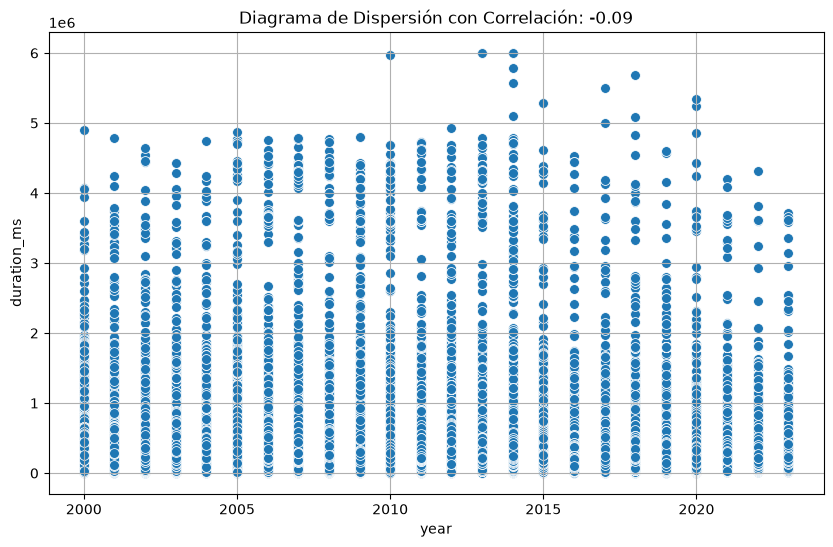

In [66]:
grafico_dispersion_con_correlacion(archivo,"year","duration_ms",mostrar_correlacion= True)

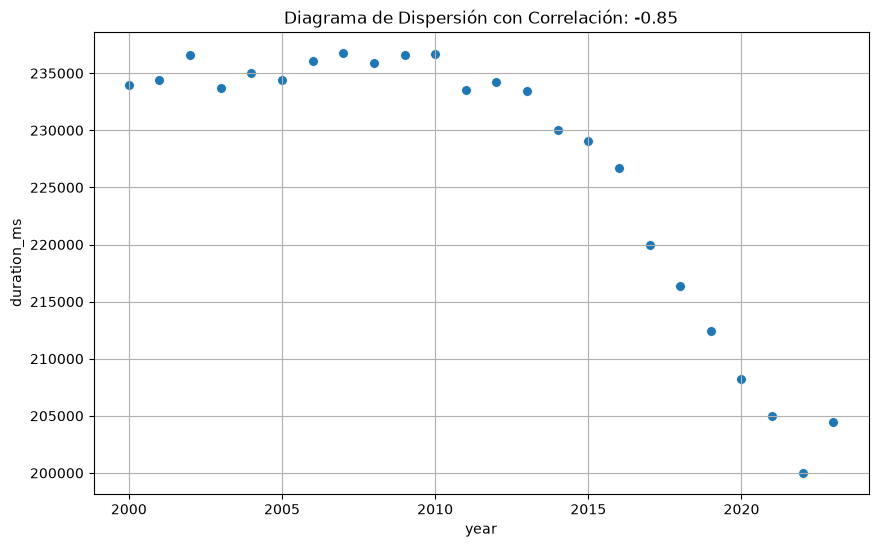

In [67]:
grafico_dispersion_con_correlacion(df1,"year","duration_ms",mostrar_correlacion= True)

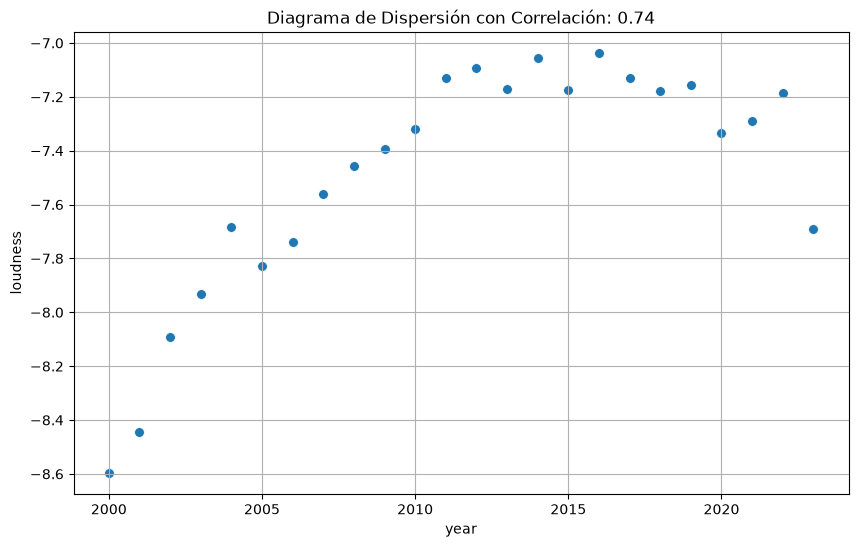

In [68]:
grafico_dispersion_con_correlacion(df1,"year","loudness",mostrar_correlacion= True)

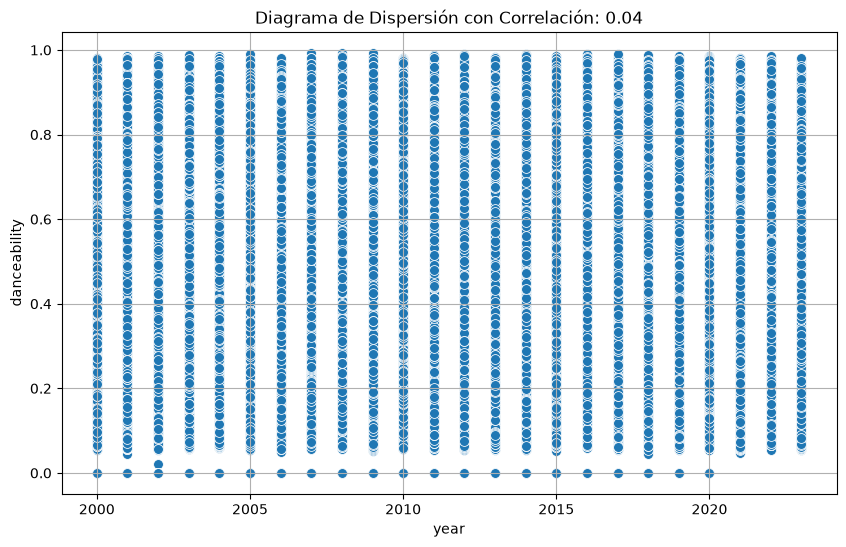

In [19]:
grafico_dispersion_con_correlacion(archivo,'year','danceability',mostrar_correlacion=True)

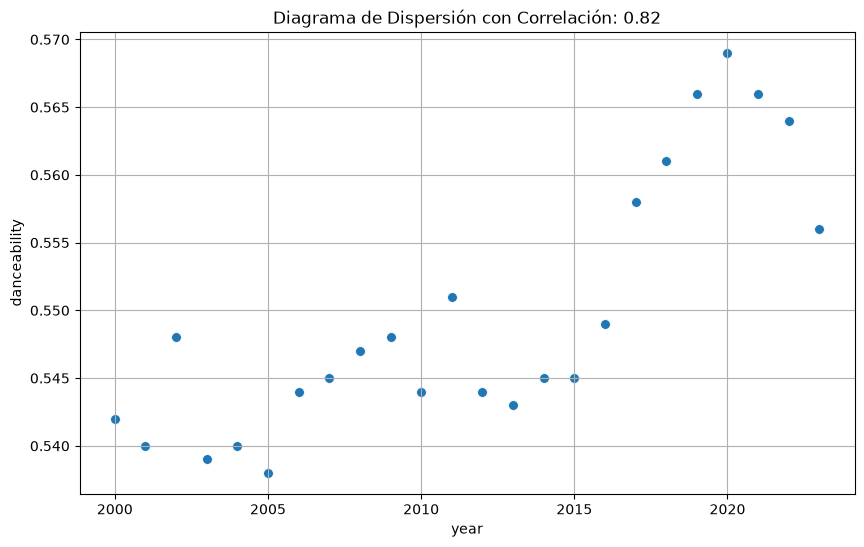

In [23]:
grafico_dispersion_con_correlacion(df1,'year','danceability',mostrar_correlacion=True)

In [27]:
pearsonr(df1['year'],df1['danceability'])

PearsonRResult(statistic=np.float64(0.8165288919073781), pvalue=np.float64(1.137842925707787e-06))

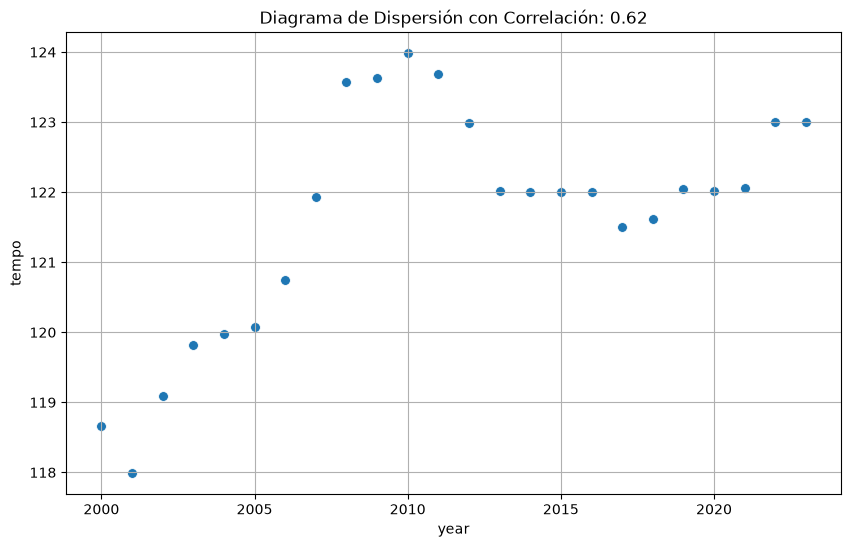

In [75]:
grafico_dispersion_con_correlacion(df1,'year','tempo',mostrar_correlacion=True)

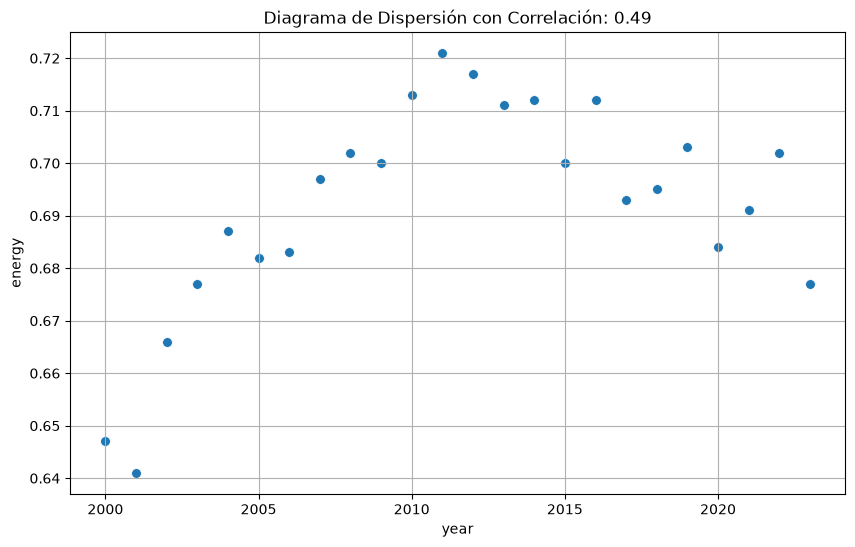

In [78]:
grafico_dispersion_con_correlacion(df1,'year','energy',mostrar_correlacion=True)

In [16]:
df2=archivo[['duration_ms','year']]
df2=pd.DataFrame(df2)
df2

,duration_ms,year
0,240166,2012
1,216387,2012
2,158960,2012
3,304293,2012
4,244320,2012
...,...,...
1473391,344013,2011
1473392,285067,2011
1473393,214253,2011
1473394,239133,2011


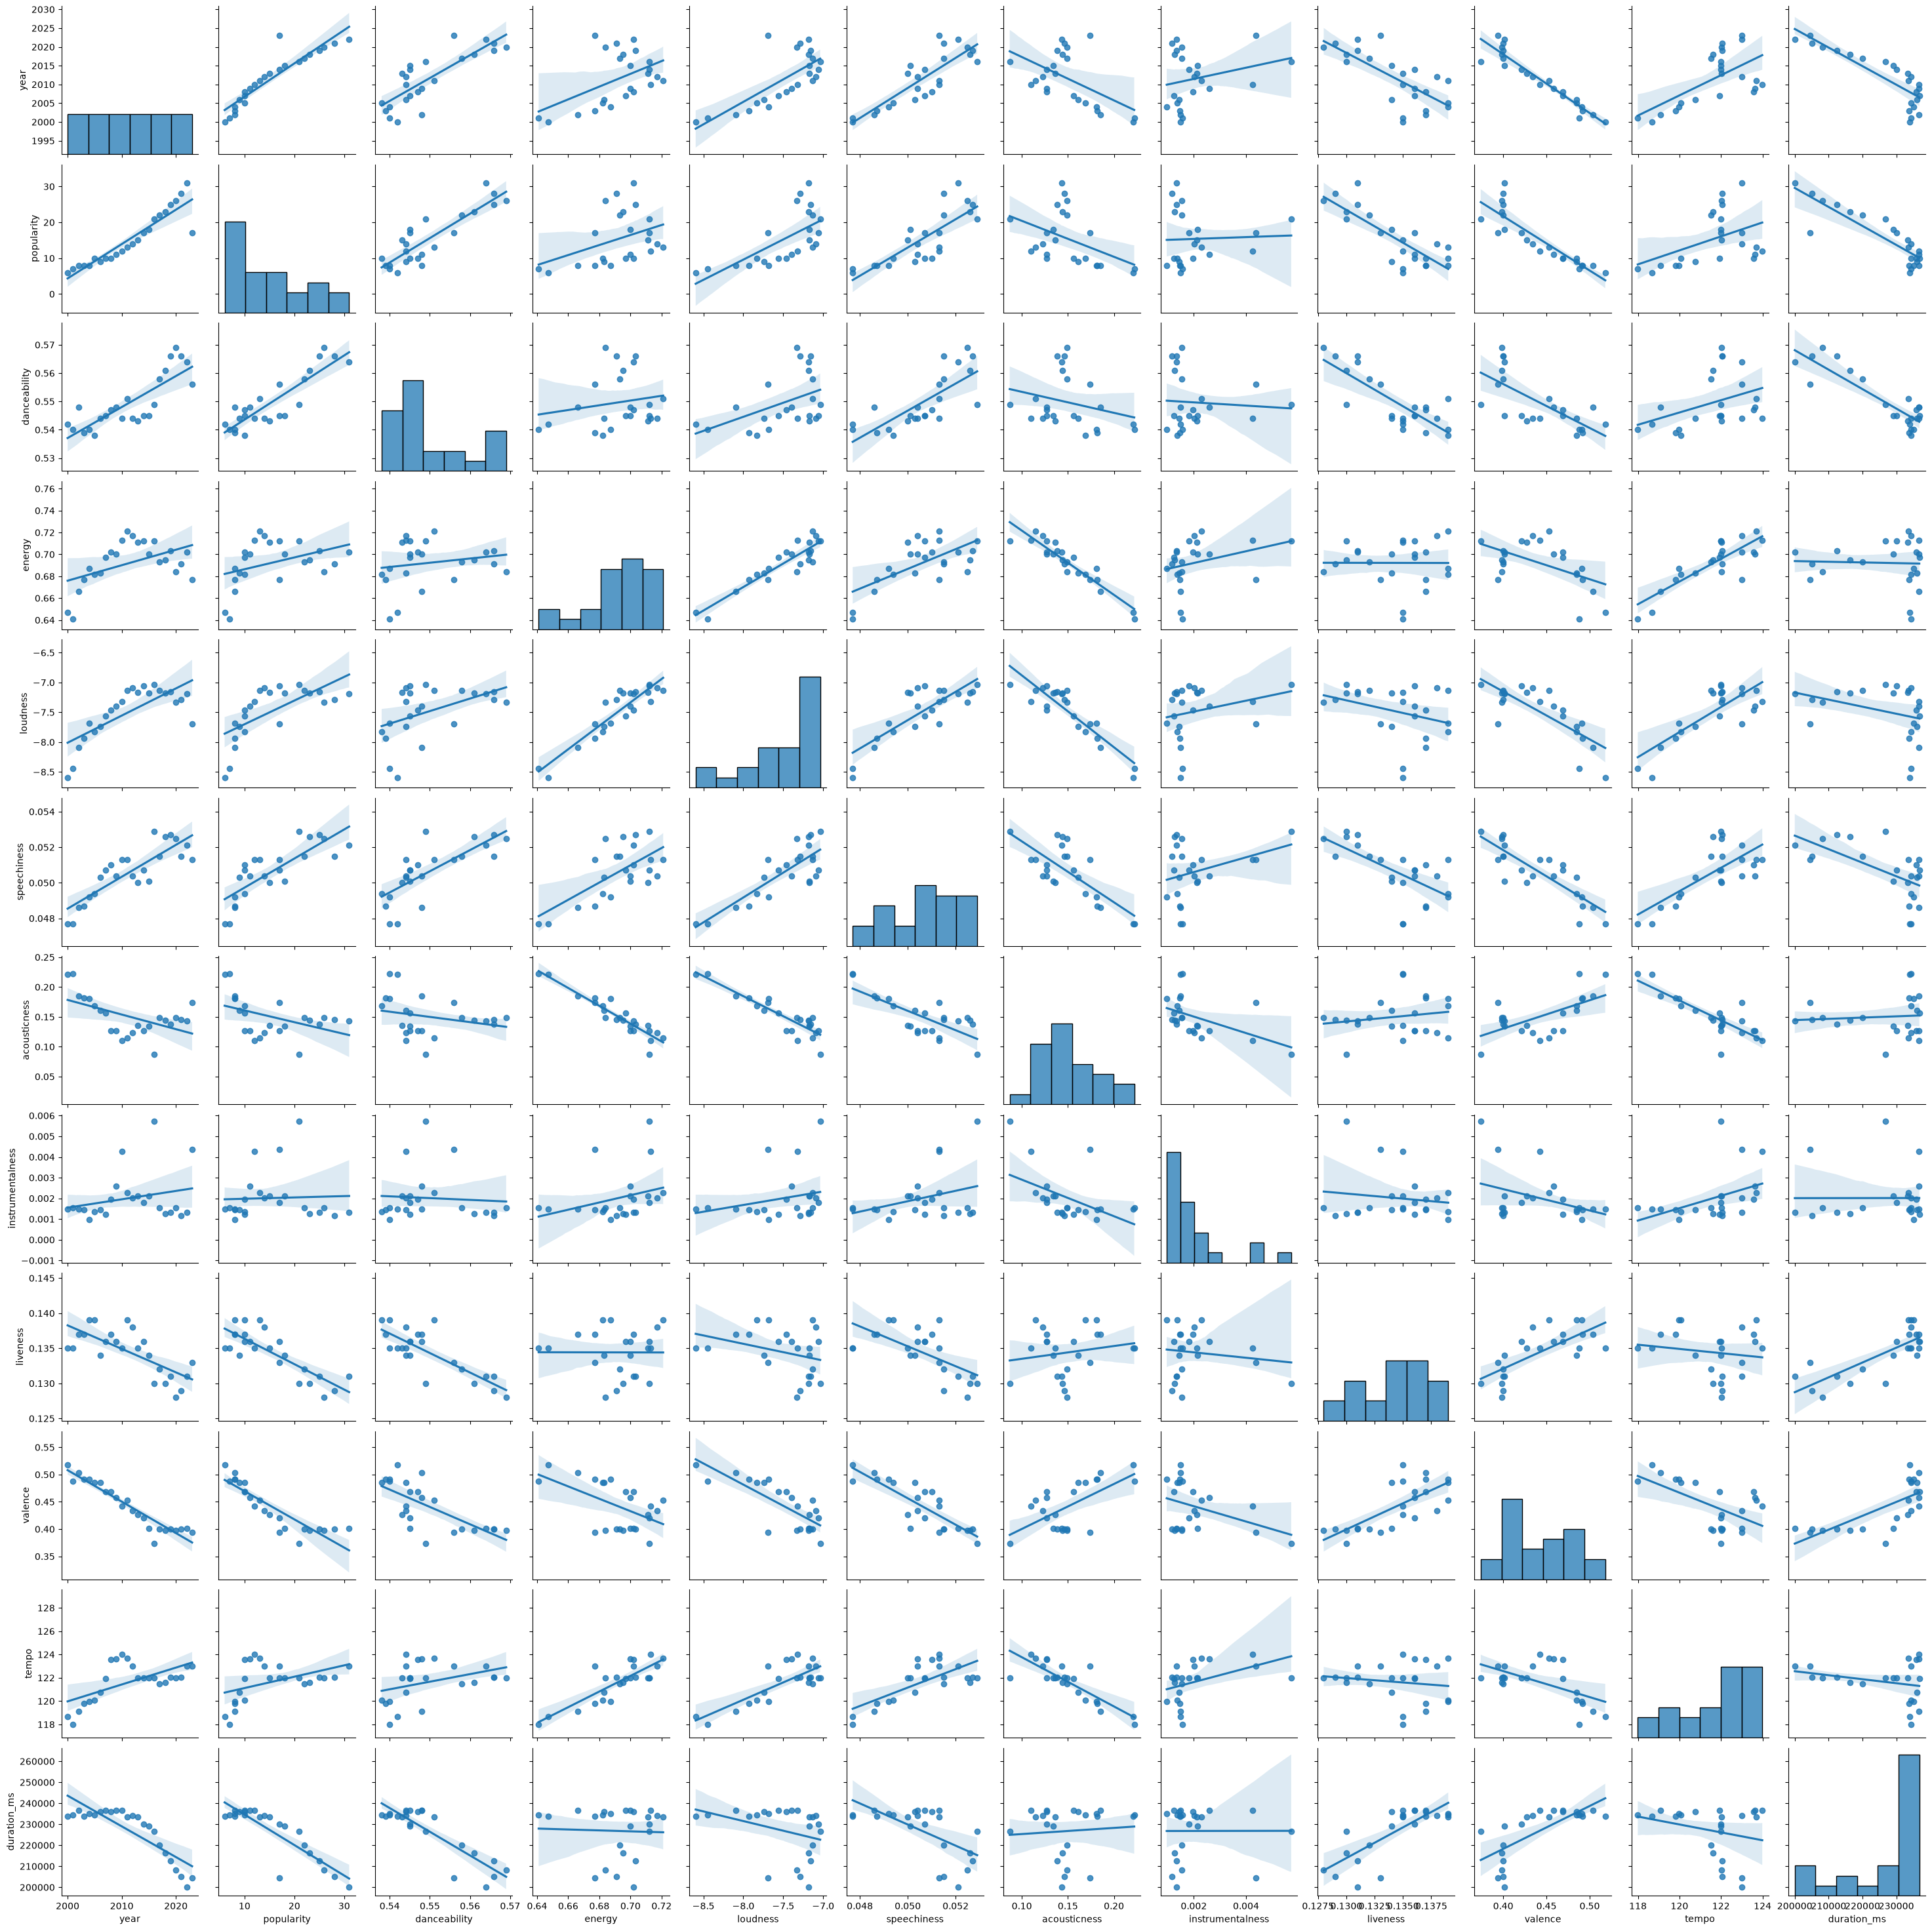

In [77]:
sns.pairplot(df1, kind='reg')

In [49]:
corr = df1.select_dtypes(include='number').corr()

# Obtener parejas de variables con correlación positiva
correlaciones_positivas = (
    corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    .stack()
    .reset_index()
)

correlaciones_positivas.columns = ['Variable 1', 'Variable 2', 'Correlación']

correlaciones_positivas = correlaciones_positivas[
    correlaciones_positivas['Correlación'] > 0
].sort_values('Correlación', ascending=False)

correlaciones_positivas.where(correlaciones_positivas['Correlación']>0.5).dropna()
#correlaciones desde medias a fuertes

,Variable 1,Variable 2,Correlación
1,year,popularity,0.922645
40,energy,loudness,0.918803
14,popularity,danceability,0.878825
5,year,speechiness,0.847806
46,energy,tempo,0.834716
2,year,danceability,0.816529
53,loudness,speechiness,0.815291
17,popularity,speechiness,0.802966
58,loudness,tempo,0.790835
107,liveness,duration_ms,0.786524


In [ ]:
corr = archivo.select_dtypes(include='number').corr()

# obtener parejas de variables con correlación positiva
correlaciones_positivas = (
    corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    .stack()
    .reset_index()
)

correlaciones_positivas.columns = ['Variable 1', 'Variable 2', 'Correlación']

correlaciones_positivas = correlaciones_positivas[
    correlaciones_positivas['Correlación'] > 0
].sort_values('Correlación', ascending=False)

df4=correlaciones_positivas.where(correlaciones_positivas['Correlación']>0.5).dropna()
df4.where(df4['Variable 1']=='year').dropna()
#correlaciones desde medias hasta fuertes dependientes del año. confirman la hipotesis principal


,Variable 1,Variable 2,Correlación
1,year,popularity,0.991361
5,year,speechiness,0.982952
2,year,danceability,0.962031
4,year,loudness,0.908702
10,year,tempo,0.853505
3,year,energy,0.746489
7,year,instrumentalness,0.524939


In [48]:
archivo[['popularity','danceability']].corr()

,popularity,danceability
popularity,1.000000,0.985419
danceability,0.985419,1.000000


In [43]:
df4.where(df4['Variable 1']=='popularity').dropna()

,Variable 1,Variable 2,Correlación
14,popularity,danceability,0.985419
17,popularity,speechiness,0.961324
16,popularity,loudness,0.867237
22,popularity,tempo,0.790833
15,popularity,energy,0.679559


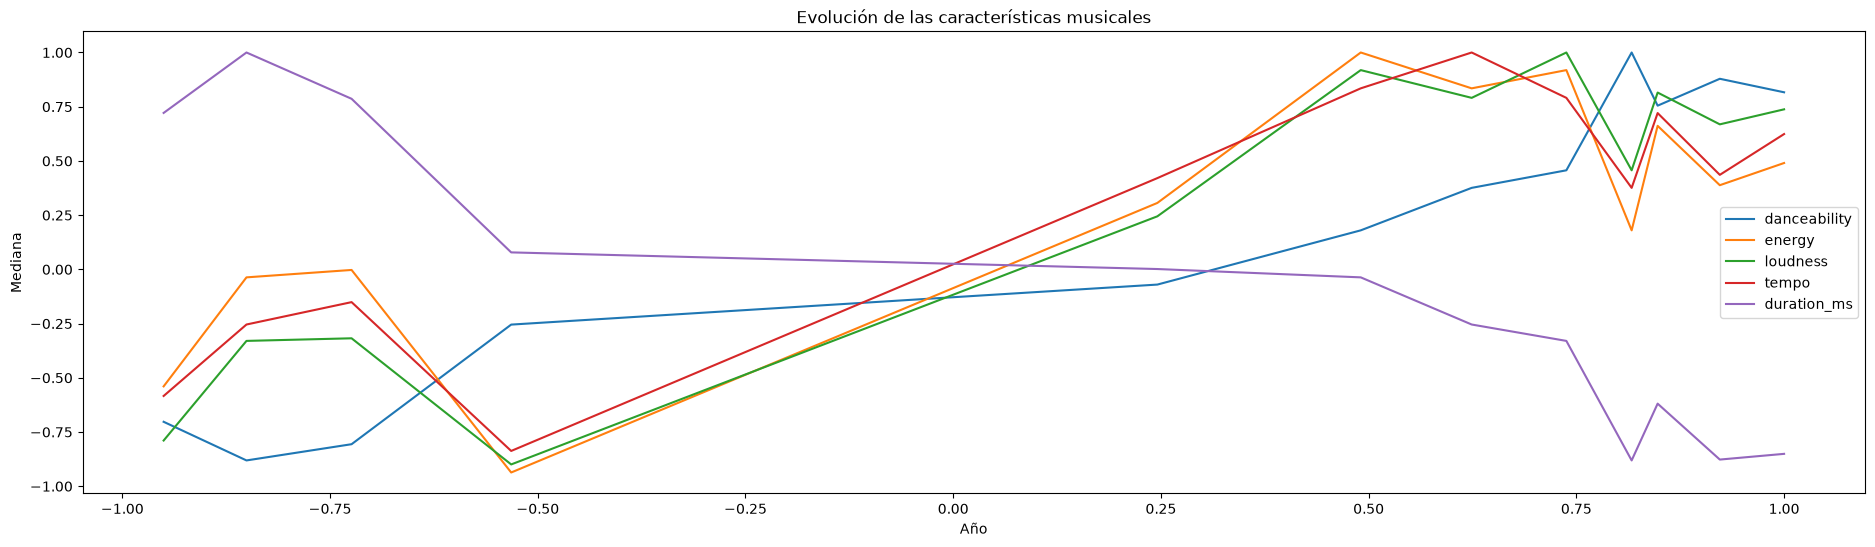

In [56]:
columnas = ['danceability', 'energy', 'loudness', 'tempo','duration_ms']

df1 = archivo.groupby('year')[columnas].median()

df1.plot(figsize=(23, 6))

plt.title('Evolución de las características musicales')
plt.xlabel('Año')
plt.ylabel('Mediana')
plt.show()


<Axes: >

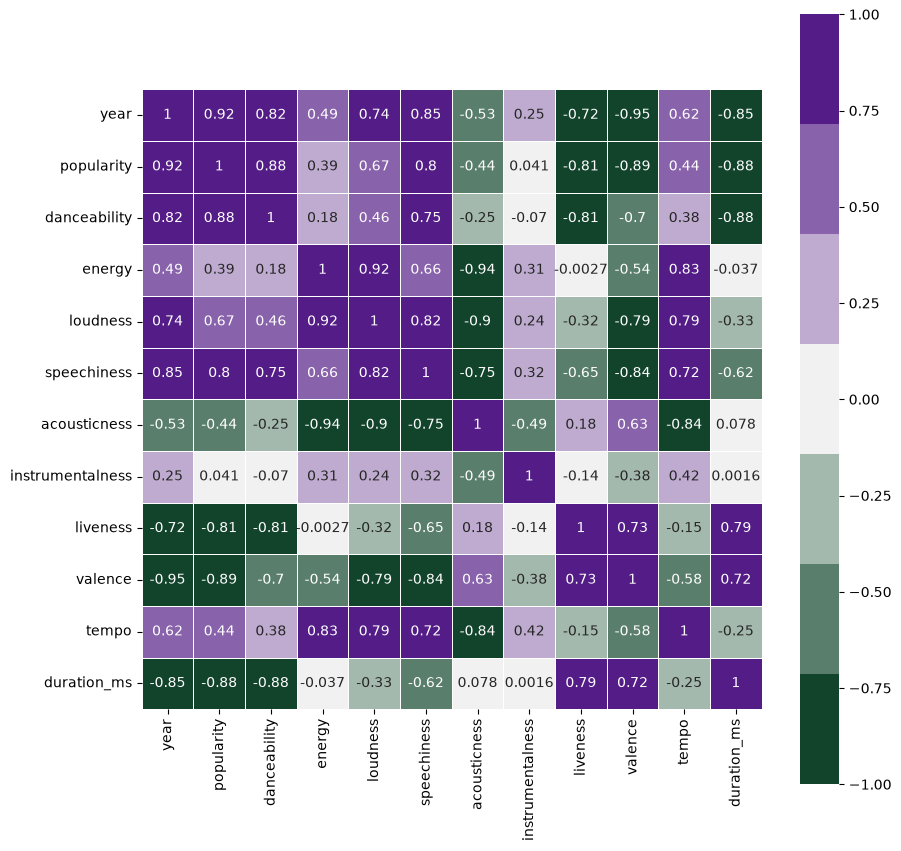

In [69]:
plt.figure(figsize=(10, 10))

sns.heatmap(
    df1.corr(),
    vmin=-1,
    vmax=1,
    cmap=sns.diverging_palette(145, 280, s=85, l=25, n=7),
    annot=True,
    square=True,
    linewidths=.5
)

<Axes: >

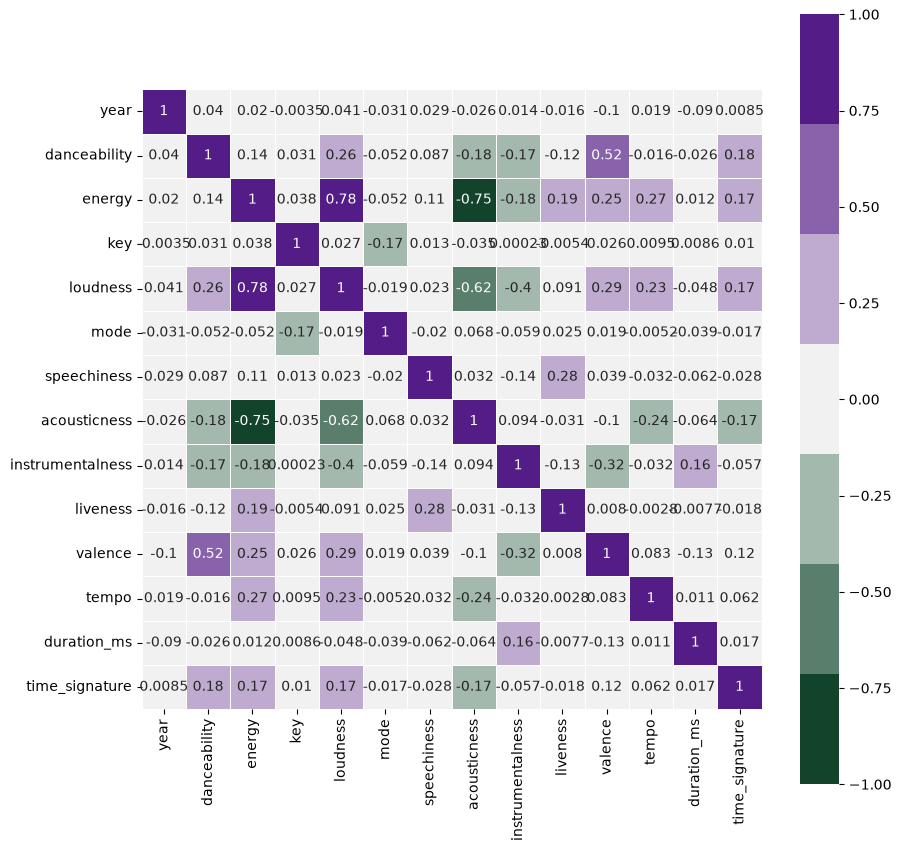

In [73]:
plt.figure(figsize=(10, 10))

sns.heatmap(
    archivo.iloc[:,5:].corr(),
    vmin=-1,
    vmax=1,
    cmap=sns.diverging_palette(145, 280, s=85, l=25, n=7),
    annot=True,
    square=True,
    linewidths=.5
)

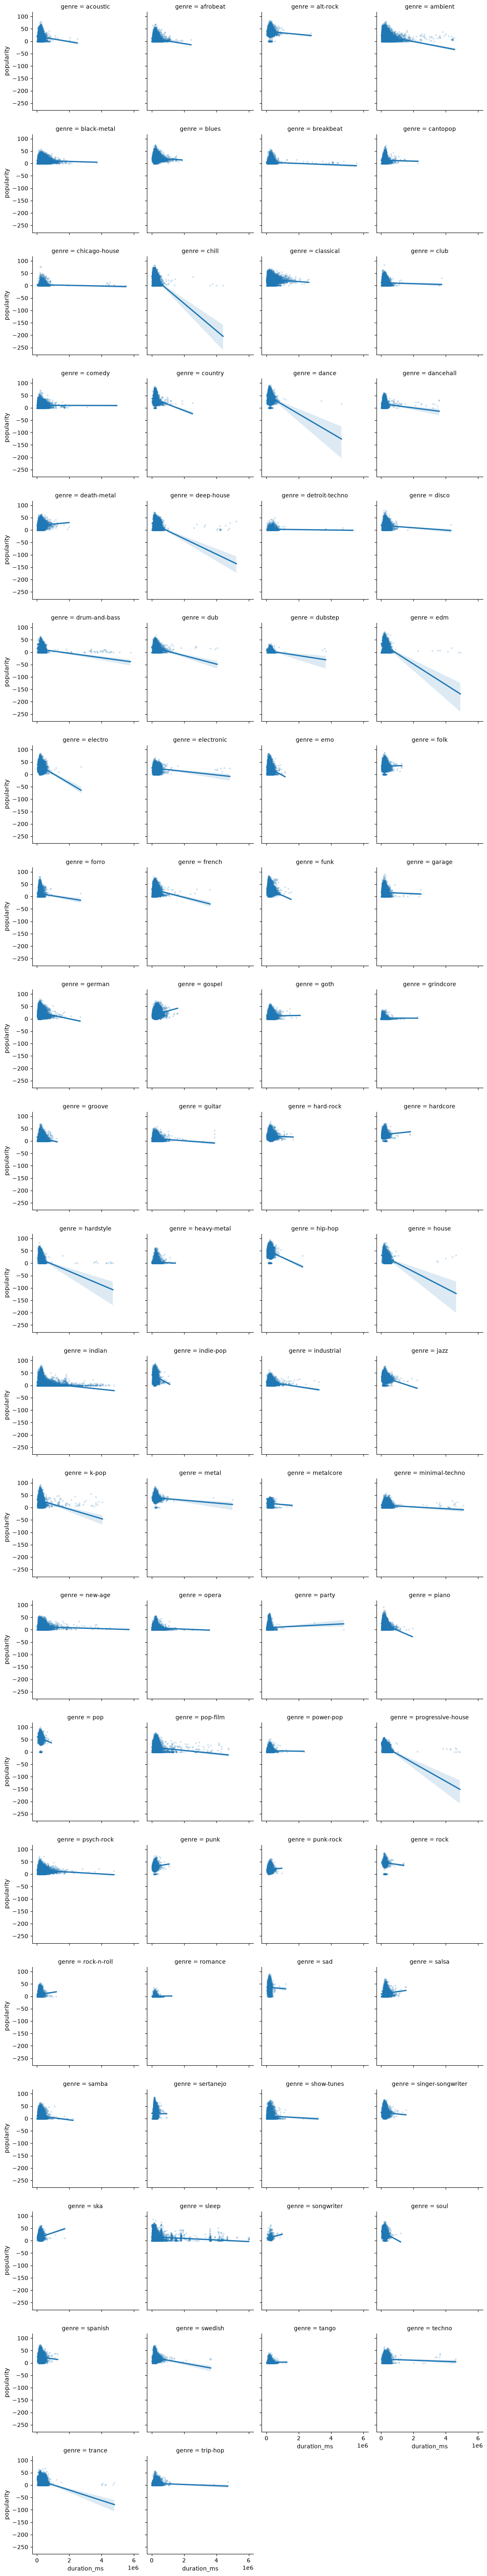

In [ ]:
sns.lmplot(
    data=archivo,
    x='duration_ms',
    y='popularity',
    col='genre',
    col_wrap=4,
    scatter_kws={'alpha': 0.15, 's': 5},
    height=3
)

plt.show()
#correlaciones de como se distribuye la popularidad según género por tiempo de duración